In [1]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from scipy import stats
from subprocess import run, PIPE
import sys
import gc
from pathlib import Path
import re
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [2]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [3]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [4]:

cesm2_tmean = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/tmean/cesm2_1990-2050_ensmean_30-60N_yearly_tmean.nc')['TREFHT']
#cesm2_tmean = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/tmean/cesm2_1990-2050_013_30-60N_yearly_tmean.nc')['TREFHT']
cesm2_tmean = cesm2_tmean[31:60,:,:]
latitude = [30,60]

land_sea_cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
land_sea_cesm2 = land_sea_cesm2[0,:,:]
indexer = ((land_sea_cesm2.lat>=latitude[0]) & (land_sea_cesm2.lat<=latitude[1]))
land_sea_cesm2 = land_sea_cesm2.where(indexer,drop=True)
land_sea_cesm2 = land_sea_cesm2.assign_coords(lat=cesm2_tmean.lat, lon=cesm2_tmean.lon)
cesm2_tmean_land = cesm2_tmean.where(land_sea_cesm2 > 0, np.nan)
lat_weights = xr.DataArray(
    np.cos(np.deg2rad(land_sea_cesm2['lat'])),
    dims=['lat'],
    coords={'lat': land_sea_cesm2['lat']}
)
cesm2_tmean_land_mean = cesm2_tmean_land.weighted(lat_weights).mean(dim=["lat", "lon"])
cesm2_tmean_land_diff = cesm2_tmean_land_mean - cesm2_tmean_land_mean[0]

In [5]:
print(cesm2_tmean_land_diff)

<xarray.DataArray 'TREFHT' (time: 29)> Size: 232B
array([0.        , 0.09544191, 0.1895155 , 0.15682273, 0.28919125,
       0.4143865 , 0.3258798 , 0.41914781, 0.5262798 , 0.57445464,
       0.57353772, 0.67079835, 0.74270914, 0.95280396, 0.8067899 ,
       1.04253431, 0.90117648, 1.02811606, 0.94165298, 1.22734159,
       1.22227441, 1.31648778, 1.28683774, 1.34762813, 1.57336479,
       1.46894068, 1.61058048, 1.66333816, 1.65230657])
Coordinates:
  * time     (time) object 232B 2021-12-31 00:00:00 ... 2049-12-31 00:00:00


In [6]:
# Folder with your files
DATA_DIR = Path("/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/cesm2_ens")

# Regex to capture the 3-digit ensemble id (e.g., 020)
pat = re.compile(r"cesm2_(\d{3})_land_daily_1_1990-2050_30-60N_precip_count_sum\.nc")

# Collect and sort files by the numeric ensemble id
files = [p for p in DATA_DIR.glob("cesm2_*_land_daily_1_1990-2050_30-60N_precip_count_sum.nc") if pat.match(p.name)]
files = sorted(files, key=lambda p: int(pat.match(p.name).group(1)))

das = []
ens_vals = []

for p in files:
    ens_id = int(pat.match(p.name).group(1))
    # If your files are pure DataArray NetCDFs, use open_dataarray:
    # da = xr.open_dataarray(p)

    # If they are Datasets containing a variable 'PRECT', use:
    da = xr.open_dataset(p)["PRECT"]

    das.append(da)
    ens_vals.append(ens_id)

# Concatenate along a new 'ens' dimension and assign the ensemble IDs as coordinates
combined = xr.concat(das, dim="ens").assign_coords(ens=("ens", ens_vals))

# Optional: ensure a predictable order/type for 'ens'
combined["ens"] = combined["ens"].astype(int)
combined = combined[:,31:60,:]
#print(combined)
# <xarray.DataArray 'PRECT' (ens: 9, year: 60, time: 184)>
# ... coords: ens, time; dims: ens, year, time

In [8]:
print(combined)

<xarray.DataArray 'PRECT' (ens: 10, year: 29, time: 184)> Size: 427kB
array([[[1243.70566835, 1270.0211721 , 1138.36809009, ...,
          907.58620125,  996.13562613, 1044.61195805],
        [1073.52635443, 1140.31512363, 1127.3828519 , ...,
          881.66174722,  878.97835733,  839.53706415],
        [ 811.05603608,  812.7956804 , 1095.00200378, ...,
          771.46481972,  635.65287325,  841.35050798],
        ...,
        [1103.0537022 ,  979.57293041, 1067.43485361, ...,
          548.5001907 ,  572.06981301,  530.85017007],
        [1139.37601685, 1082.64314129, 1056.89124595, ...,
          935.08153654,  890.79247314,  866.30411058],
        [1075.80426783, 1016.13433874, 1140.02865468, ...,
          758.73191063,  781.80355442,  824.24861226]],

       [[1211.81444431, 1096.6249744 , 1081.04225352, ...,
         1108.6975313 , 1093.05518442, 1090.82937712],
        [1114.9316222 , 1188.06729355, 1260.86486923, ...,
          667.35138008,  724.68396764,  728.12636414],
   

## CESM2 

In [7]:
latitude = [30,60]

cesm2_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
cesm2_size = cesm2_size[0,:,:]
indexer = ((cesm2_size.lat>=latitude[0]) & (cesm2_size.lat<=latitude[1]))
cesm2_size = cesm2_size.where(indexer,drop=True)
# 5) Compute percentage of grid cells for each time
cesm2_land = xr.where(cesm2_size > 0, 1, 0)
lat_weights = xr.DataArray(
    np.cos(np.deg2rad(cesm2_size['lat'])),
    dims=['lat'],
    coords={'lat': cesm2_size['lat']}
)
total_cells = cesm2_land.weighted(lat_weights).sum()


percent_cesm2 = combined / total_cells * 100  # DataArray of length time
percent_cesm2_mean = percent_cesm2.mean(dim=['ens','time'])
cesm2_lin = stats.linregress(cesm2_tmean_land_mean,percent_cesm2_mean)

print(cesm2_lin)

LinregressResult(slope=-0.5706169534680937, intercept=35.12561667431356, rvalue=-0.8639016028813211, pvalue=1.579575636870232e-09, stderr=0.06402307141446019, intercept_stderr=0.6186209766103621)


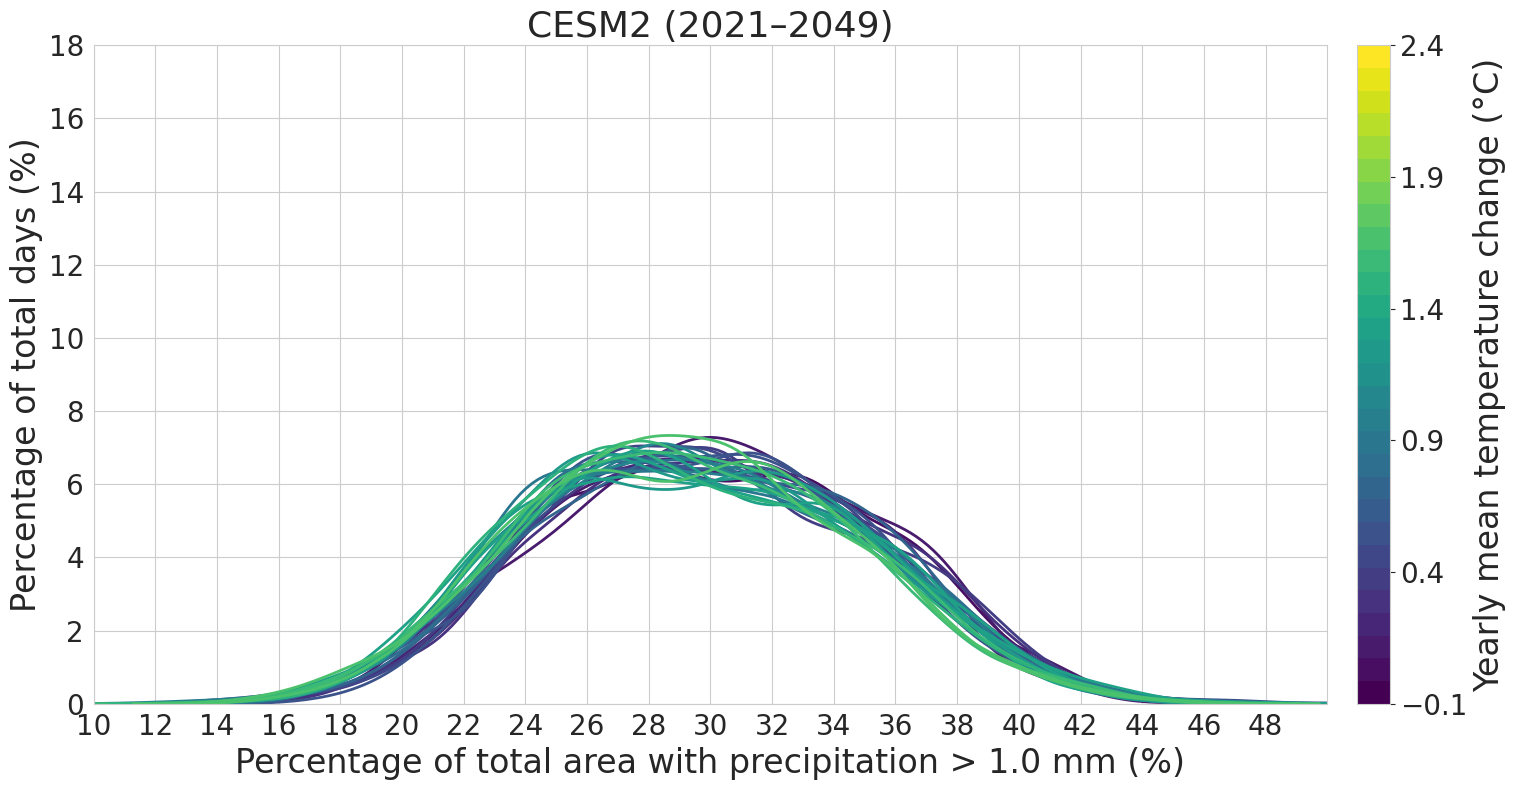

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Common x‐range + bin width
xmin, xmax = 10, 50
bin_width = 1.0

# 2) Year indices (0–29) and number of years
years = percent_cesm2.year.values
n_years = len(years)

# 3) Viridis colormap
temps = cesm2_tmean_land_diff.values
cmap = plt.get_cmap('viridis',n_years)

norm = plt.Normalize(
    vmin=-0.1,
    vmax=2.4
)

fig, ax = plt.subplots(figsize=(16, 8))
sns.set_style("whitegrid")

# Prepare to record the total weight for each year
sum_weights = []

# 4) Plot each year's KDE
for i, (yr, temp) in enumerate(zip(years, temps)):
    vals = percent_cesm2.sel(year=yr).values.ravel()
    vals = vals[~np.isnan(vals)]
    # weights that sum to 100
    w = np.ones_like(vals) * (100.0 / vals.size)
    sum_weights.append(w.sum())  # this will be 100.0 for each year

    sns.kdeplot(
        x=vals,
        weights=w,
        bw_adjust=1.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=cmap(norm(temp)),
        legend=False
    )

# 5) Rescale from “percent per unit‐x” → “percent per 0.5%‐bin”
for line, total_w in zip(ax.get_lines(), sum_weights):
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * bin_width * total_w
    line.set_data(x_vals, y_scaled)

sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)
sm.set_array([])

ticks = np.linspace(-0.1, 2.4, 6)

cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=ticks)
cbar.set_label('Yearly mean temperature change (°C)', fontsize=24)
cbar.ax.tick_params(labelsize=20)

plt.xlim(xmin, xmax)

xticks = np.arange(xmin, xmax, 2)
ax.set_xticks(xticks)



# 7) polish & save
xl = 'Percentage of total area with precipitation > 1.0 mm (%)'
ax.set_ylim(0, 18)
ax.set_xlabel(xl, fontsize=24)
ax.set_ylabel('Percentage of total days (%)', fontsize=24)
ax.set_xlim(xmin, xmax)
ax.tick_params(axis='both', which='major', labelsize=20)
plt.title('CESM2 (2021–2049)', fontsize=26)
plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_cesm2_ens_histo_precip_coverage_daily_1_temp.pdf', format='pdf',bbox_inches='tight')

plt.show()
